In [5]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
'''
Let's take a function, any function here as an example. 
e.g: 5x^2 -8x + 3
'''

def f(x):
    return 5*x**2 - 8*x + 3

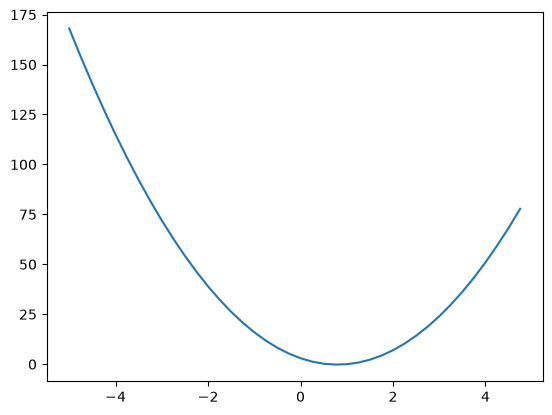

In [3]:
# randomly take numbers between -5 and 5 to plot the graph of the function with those numbers
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
plt.plot(xs, ys) # gives us the relationship between x and y based on the function

In [4]:
# A derivative is explained as - if I change this variable in the expression just a little bit,
# How does it affect the final value? 
# suppose we have x, final value y = f(x) 
# we change value of x by h, h here is 0.00001
# the value of f(x+h) - f(x) is the total change in the final value
# we normalize it by dividing this change by h.

h = 0.00001
x = 3
# f(x)
# f(x+h)
# now we calculate the sensitivity
(f(x+h) - f(x))/h

22.00004999970417

In [5]:
# Now, let's take a more complex arbitrary example

h = 0.0001

# inputs
a = 2.0
b = -3.0
c = 10

# d = 1*b + c

d1 = a*b + c
a = a + h
d2 = a*b + c

d3 = a*b + c
b = b + h
d4 = a*b + c

d5 = a*b + c
c = c + h
d6 = a*b + c

print(d1, d2, (d2 - d1)/h)
print(d3, d4, (d4 - d3)/h)
print(d5, d6, (d6 - d5)/h)

4.0 3.999699999999999 -3.000000000010772
3.999699999999999 3.99990001 2.0001000000124947
3.99990001 4.00000001 0.9999999999976694


In [41]:
# Now, let's see how micro-grad is built. It is essentially this class - which is
# the heart of the 'neural network'.
class Value:
    def __init__(self, data, _children = (), _op = '', label = ''):
        self.data = data
        self._prev = set(_children) # who are the children of this operation?
        self._op = _op # what is the operation?
        self.label = label # for the graph
        self.grad = 0

        self._backward = lambda: None
        '''
        the backward function basically does the derivative for us - it is implemented
        differently for different operations below. 
        '''

    def __repr__(self):
        '''Python uses this class to print the value it holds for data'''
        return f"data value = ({self.data})"

    def __add__(self, other):
        ''' custom implementation of addition'''
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')
        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out
        
    def __mul__(self, other):
        ''' custom implementation of multiplication'''
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __rmul__(self, other):
        return self * other

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supports int / float"
        out = Value(self.data**other, (self, ), f'**{other}')
        
        def _backward():
            self.grad = (other * self.data ** (other - 1)) * out.grad
        out._backward = _backward

        return out

    def __truediv__(self, other):
        return self * other**-1

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')
        
        def _backward():
            self.grad = out.data * out.grad
        out._backward = _backward

        return out
        
    def tanh(self):
        '''
        The tanh function is an activation function. It is responsible to squash
        the final value into an output between -1 and 1.
        '''
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, (self, ),'tanh')
        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        return out

    def __neg__(self):
        return self * -1
        
    def __sub__(self, other):
        return self + (-other)
    
    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()


In [42]:
a = Value(2.0)
b = Value(4.0)
a - b

data value = (-2.0)

In [2]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right

  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

In [9]:
def lol():
    h = 0.0001

    a = Value(2.0, label = 'a')
    b = Value(-3.0, label = 'b' )
    c = Value(10.0, label = 'c')
    f = Value(-2.0, label = 'f')
    e = a*b; e.label = 'e'
    d = e + c; d.label = 'd'
    L = d * f ; L.label = 'L'
    L1 = L.data

    a = Value(2.0 + h, label = 'a')
    b = Value(-3.0, label = 'b' )
    c = Value(10.0, label = 'c')
    f = Value(-2.0, label = 'f')
    e = a*b; e.label = 'e'
    d = e + c; d.label = 'd'
    L = d * f ; L.label = 'L'
    L2 = L.data

    print((L2 - L1) / h)
lol()

6.000000000021544


In [43]:
# now, we are going to move towards back-propogation in a neural network.
# here, we get some inputs x1, x2, ... and the neurons are basically weights w1, w2,...
# we then multiply the weights by the inputs, apply an activation function (squashes the value between 0 and 1 (e.g: sigmoid, tanh)) and spit out an output.
# inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1, w2
w1 = Value(-3.0,label='w1')
w2 = Value(1.0, label='w2')

# bias - this decides how 'trigger-happy' the activation function is, i.e, for small inputs, is it very sensitive or do we require large inputs for it to matter
b = Value(6.88137358, label='b')

# multiply inputs with weights:
x1w1 = x1*w1; x1w1.label = 'x1w1'
x2w2 = x2*w2; x2w2.label = 'x2w2'

# add the weighted inputs:
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'

# add the bias
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'

o.backward()

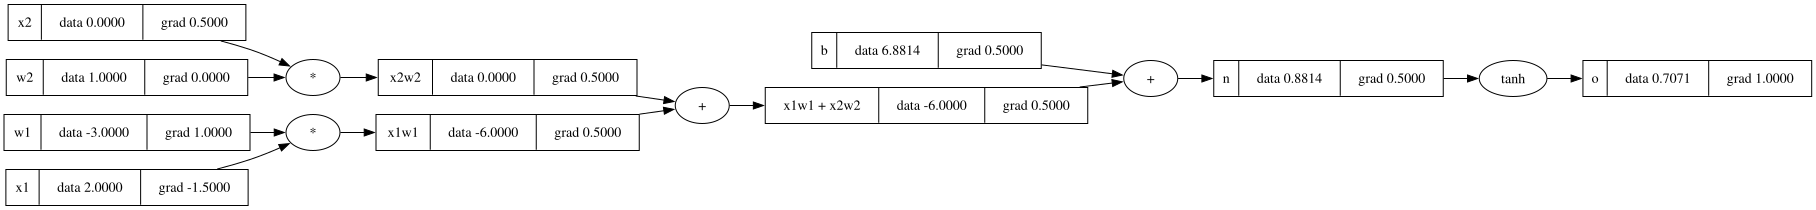

In [44]:
draw_dot(o)

In [12]:
o.grad = 1.0
n.grad = 0.5

x1w1x2w2.grad = 0.5
b.grad = 0.5

x1w1.grad = 0.5
x2w2.grad = 0.5

x2.grad = w2.data * x2w2.grad
w2.grad = x2.data * x2w2.grad

x1.grad = w1.data * x1w1.grad
w1.grad = x1.data * x1w1.grad
# o = tanh(n)
# do/dn = 1-o**2

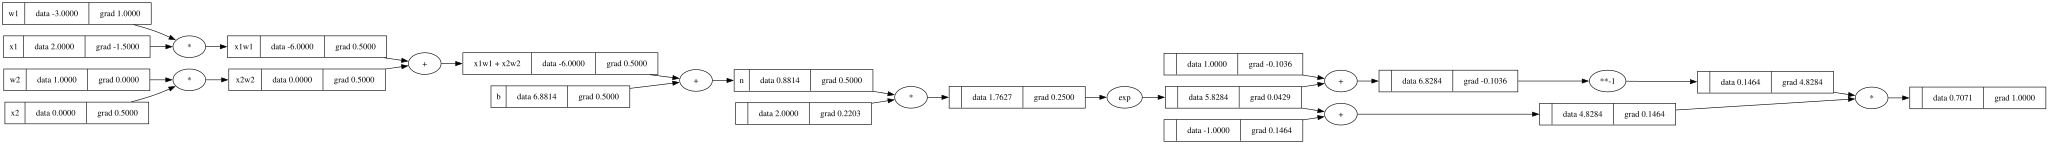

In [46]:
# now, we are going to move towards back-propogation in a neural network.
# here, we get some inputs x1, x2, ... and the neurons are basically weights w1, w2,...
# we then multiply the weights by the inputs, apply an activation function (squashes the value between 0 and 1 (e.g: sigmoid, tanh)) and spit out an output.
# inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1, w2
w1 = Value(-3.0,label='w1')
w2 = Value(1.0, label='w2')

# bias - this decides how 'trigger-happy' the activation function is, i.e, for small inputs, is it very sensitive or do we require large inputs for it to matter
b = Value(6.88137358, label='b')

# multiply inputs with weights:
x1w1 = x1*w1; x1w1.label = 'x1w1'
x2w2 = x2*w2; x2w2.label = 'x2w2'

# add the weighted inputs:
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'

# add the bias
n = x1w1x2w2 + b; n.label = 'n'
# o = n.tanh(); o.label = 'o'

e = (2*n).exp()
o = (e - 1)/(e + 1)

o.backward()
draw_dot(o)